# F6: the oil wave on the real graph

How a move of the oil price travels through the 18-company market built on `real_v1`
(WTI → oil producers COP, EOG → refiners VLO, MPC → airlines DAL, UAL and trucking ODFL).

Two views:

1. **A clean step** (`configs/f6_oil_step.yaml`): every external signal is frozen at its level of 2 January 2024 and
   oil alone steps +20% or −20% at session 10. Nothing else happens, so every price move is the wave.
2. **The real signals of 2024–2025** (experiment E5, `configs/f6_e5.yaml`): the average market reaction on the
   days with the largest oil moves.

The notebook reads K3 run logs under `runs/f6/v1/` (not committed). The numbers are quick-look diagnostics plus the
wave metrics of `marketsim.metrics` (D1). Calibration and parameters: `docs/guides/f6_full_network.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from marketsim.data import api
from marketsim.data import schemas as S
from marketsim.experiments.run import run_experiment
from marketsim.graph.api import load_graph
from marketsim.metrics import wave_metrics
from marketsim.sim.log_schema import load_run

plt.rcParams["figure.dpi"] = 80
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "runs" / "f6" / "v1"
SHOCK = 10
GRAPH = load_graph("real_v1")
TICKERS = GRAPH.companies()
# Distance from oil along the edges of the graph.
LEVELS = {"COP": 1, "EOG": 1, "VLO": 2, "MPC": 2, "DAL": 3, "UAL": 3, "ODFL": 3}
OIL_CLUSTER = list(LEVELS)
OTHERS = [t for t in TICKERS if t not in LEVELS]

# The two synthetic scenarios: all external signals flat at their first real level, oil steps at SHOCK.
real = api.load_external("real_2024_2025")
for name, factor in (("f6_oil_up", 1.2), ("f6_oil_down", 0.8)):
    if not api.table_path(S.EXTERNAL, scenario=name).exists():
        table = pd.DataFrame({c: np.full(40, float(real[c].iloc[0])) for c in real.columns if c != "date"},
                             index=pd.RangeIndex(40, name="session"))
        table.loc[SHOCK:, "wti"] *= factor
        table.insert(0, "date", pd.Series(pd.NaT, index=table.index, dtype="datetime64[ns]"))
        api.write_table(table, S.EXTERNAL, scenario=name)
if not (RESULTS / "oil_step" / "summary.csv").exists():
    run_experiment(ROOT / "configs" / "f6_oil_step.yaml", RESULTS / "oil_step", workers=4)  # 20 runs, ~1 min each
step = pd.read_csv(RESULTS / "oil_step" / "summary.csv")
step.groupby("external").size()

external
f6_oil_down    10
f6_oil_up      10
dtype: int64

## 1. What the graph says should happen

Reference move of every company for oil +20% (the path R: everyone applies the full weights instantly and exactly).
The airlines are the interesting case: oil hurts them directly and helps them through the refiners' share prices,
so their net reference move is small.

In [2]:
def intraday(run_dir):
    # Mid price (ticks) and reference per snapshot time, one column per ticker; one-sided book -> last mid.
    book = pd.read_parquet(run_dir / "book.parquet", columns=["t", "asset", "best_bid", "best_ask"])
    val = pd.read_parquet(run_dir / "valuations.parquet", columns=["t", "asset", "reference", "v_mean"])
    ok = (book.best_bid > 0) & (book.best_ask > 0)
    book = book.assign(mid=np.where(ok, (book.best_bid + book.best_ask) / 2, np.nan))
    mid = book.pivot(index="t", columns="asset", values="mid").ffill()
    ref = val.pivot(index="t", columns="asset", values="reference")
    vmean = val.pivot(index="t", columns="asset", values="v_mean")
    for frame in (mid, ref, vmean):
        frame.columns = TICKERS
    return mid, ref, vmean


def log_moves(run_dir):
    # ln(P / P before the shock), the same for R and for the mean valuation of the valuers.
    out = []
    for frame in intraday(run_dir):
        before = frame.loc[(frame.index >= SHOCK - 2) & (frame.index < SHOCK)].mean()
        out.append(np.log(frame / before))
    return out


paths = {}
for external, group in step.groupby("external"):
    moves = [log_moves(RESULTS / "oil_step" / run_id) for run_id in group.run_id]
    paths[external] = [pd.concat([m[k] for m in moves]).groupby(level=0).mean() for k in range(3)]
    paths[external].append(pd.concat([m[0] for m in moves]).groupby(level=0).std())

ref_move = pd.DataFrame({e: paths[e][1].iloc[-1] for e in paths}).rename(
    columns={"f6_oil_up": "R move, oil +20%", "f6_oil_down": "R move, oil -20%"})
ref_move.insert(0, "distance from oil", pd.Series(LEVELS))
ref_move.sort_values("R move, oil +20%", ascending=False).round(4)

,distance from oil,"R move, oil -20%","R move, oil +20%"
EOG,1.0,-0.1232,0.1007
COP,1.0,-0.1148,0.0938
VLO,2.0,-0.0958,0.0783
MPC,2.0,-0.0777,0.0635
NVDA,NaN,0.0000,0.0000
NEM,NaN,0.0000,0.0000
AMD,NaN,0.0000,0.0000
FCX,NaN,0.0000,0.0000
NEE,NaN,0.0000,0.0000
DUK,NaN,0.0000,0.0000


## 2. The clean wave, company by company

Mean over 10 seeds (band: ± one standard deviation between seeds). Solid: price on our exchange; dashed: reference
R; dotted: mean valuation of the valuers that follow the company. Top row: oil +20%; bottom row: oil −20%.

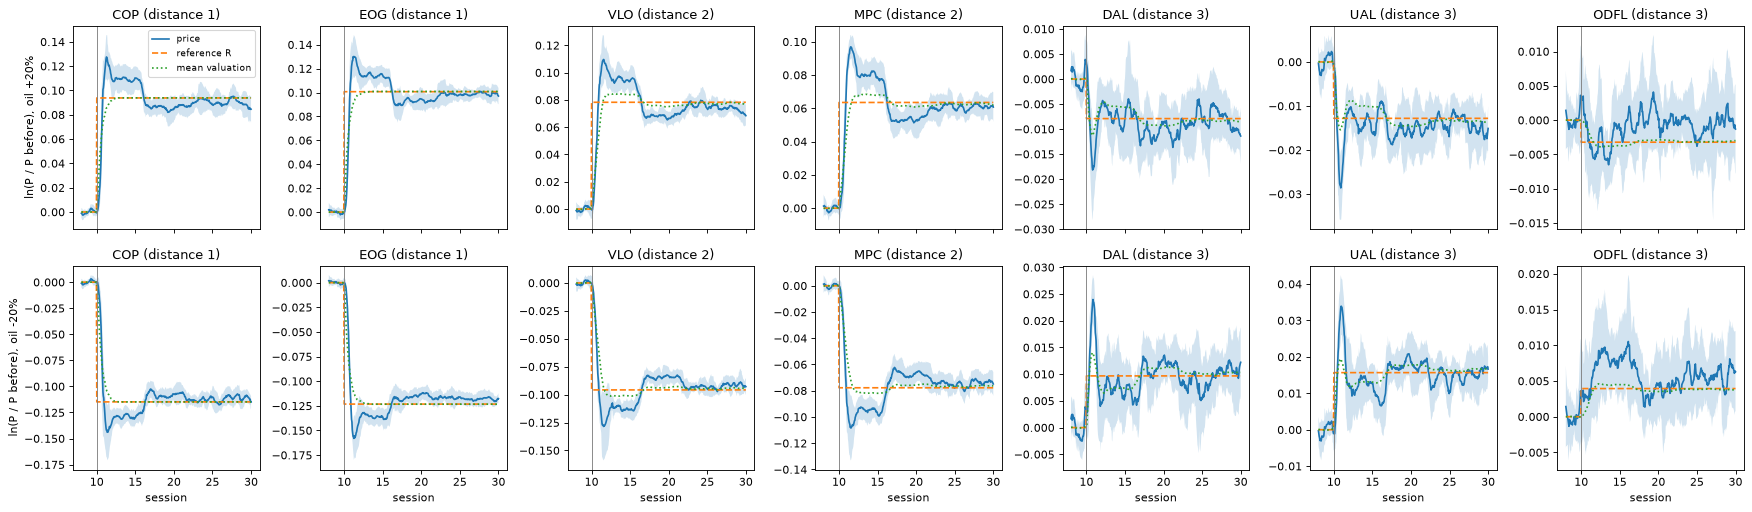

In [3]:
fig, axes = plt.subplots(2, 7, figsize=(22, 6.5), sharex=True)
for row, external in zip(axes, ("f6_oil_up", "f6_oil_down")):
    mid, ref, vmean, spread = paths[external]
    window = (mid.index >= SHOCK - 2) & (mid.index <= SHOCK + 20)
    for ax, ticker in zip(row, OIL_CLUSTER):
        x = mid.index[window]
        ax.fill_between(x, (mid[ticker] - spread[ticker])[window], (mid[ticker] + spread[ticker])[window], alpha=0.2)
        ax.plot(x, mid[ticker][window], label="price")
        ax.plot(x, ref[ticker][window], "--", label="reference R")
        ax.plot(x, vmean[ticker][window], ":", label="mean valuation")
        ax.axvline(SHOCK, color="grey", lw=0.8)
        ax.set_title(f"{ticker} (distance {LEVELS[ticker]})")
axes[0, 0].legend(fontsize=8)
axes[0, 0].set_ylabel("ln(P / P before), oil +20%")
axes[1, 0].set_ylabel("ln(P / P before), oil -20%")
for ax in axes[1]:
    ax.set_xlabel("session")
plt.tight_layout()
plt.show()

## 3. The wave as a picture: who has moved, and when

Share of the own reference move that the price has covered (1 = the price moved exactly as much as R), mean of both
directions and all seeds. Only companies whose reference moves by more than 2% are shown as shares; for the rest
the share is noise divided by a small number.

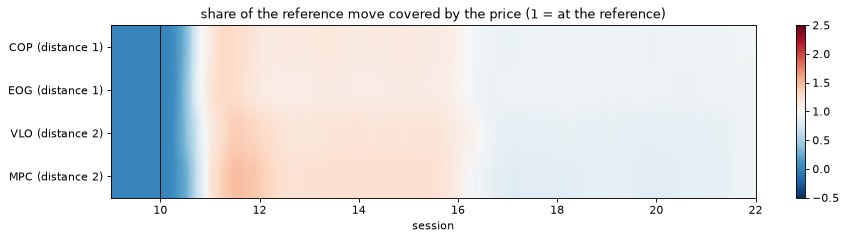

,distance,first reaches 50% (sessions after the shock),first reaches 100%,share at end of day 0,share at end of day 1,peak share,"share, sessions 20-30"
COP,1.0,0.60,0.85,1.10,1.17,1.30,0.96
EOG,1.0,0.60,0.85,1.17,1.14,1.29,0.96
VLO,2.0,0.60,0.95,1.07,1.30,1.37,0.94
MPC,2.0,0.65,0.95,1.08,1.39,1.46,0.94


In [4]:
share = {}
for external in paths:
    mid, ref = paths[external][0], paths[external][1]
    share[external] = mid / ref.iloc[-1]
share = (share["f6_oil_up"] + share["f6_oil_down"]) / 2
big = [t for t in OIL_CLUSTER if abs(ref_move.loc[t, "R move, oil +20%"]) > 0.02]
grid = share.loc[(share.index >= SHOCK - 1) & (share.index <= SHOCK + 12), big]
fig, ax = plt.subplots(figsize=(13, 2.8))
im = ax.imshow(grid.T.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-0.5, vmax=2.5,
               extent=[grid.index[0], grid.index[-1], len(big), 0])
ax.set_yticks(np.arange(len(big)) + 0.5, [f"{t} (distance {LEVELS[t]})" for t in big])
ax.axvline(SHOCK, color="k", lw=0.8)
ax.set_xlabel("session")
ax.set_title("share of the reference move covered by the price (1 = at the reference)")
plt.colorbar(im, ax=ax)
plt.show()

def first_reach(s, level):
    # Sessions after the shock until the share first reaches `level`; NaN if it never does (argmax would say 0).
    hit = (s >= level).to_numpy()
    return s.index[hit.argmax()] - SHOCK if hit.any() else np.nan


rows = {}
for ticker in big:
    s = share[ticker].loc[share.index >= SHOCK]
    rows[ticker] = {
        "distance": LEVELS[ticker],
        "first reaches 50% (sessions after the shock)": first_reach(s, 0.5),
        "first reaches 100%": first_reach(s, 1.0),
        "share at end of day 0": s.loc[s.index < SHOCK + 1].iloc[-1],
        "share at end of day 1": s.loc[s.index < SHOCK + 2].iloc[-1],
        "peak share": s.max(),
        "share, sessions 20-30": s.loc[(s.index >= SHOCK + 20)].mean(),
    }
pd.DataFrame(rows).T.round(2)

## 4. Wave metrics of D1 (`marketsim.metrics.wave_metrics`)

Completeness, overshoot, lag and half-life of the valuation error for the companies with a clear reference move;
median over the 20 runs. `step=0.25` sessions for the lag.

In [5]:
records = []
for run in step.itertuples():
    log = load_run(RESULTS / "oil_step" / run.run_id)
    for ticker in big:
        metrics = wave_metrics(log, TICKERS.index(ticker), t0=float(SHOCK), step=0.25, end_window=5.0)
        records.append({"ticker": ticker, "external": run.external, **metrics})
wave = pd.DataFrame(records)
wave.groupby("ticker")[[c for c in wave.columns if c not in ("ticker", "external")]].median().loc[big].round(3)

,completeness,overshoot,lag_sessions,error_half_life_sessions,volatility_amplification,price_log_change,reference_log_change
ticker,,,,,,,
COP,0.980,0.034,0.75,0.596,1.267,-0.007,-0.011
EOG,0.956,0.030,0.75,0.561,1.282,-0.008,-0.011
VLO,0.948,0.032,0.75,0.588,1.314,-0.005,-0.009
MPC,0.941,0.034,1.00,0.637,1.418,-0.006,-0.007


## 5. Companies outside the oil cluster

Their reference does not move at all. Any move here is a spillover through shared wallets, rebalancing and the
stop-loss, not through the graph (question P6; the proper experiment is E6).

In [6]:
rows = {}
for external in paths:
    mid = paths[external][0]
    after = mid.loc[(mid.index >= SHOCK) & (mid.index < SHOCK + 5), OTHERS].mean()
    late = mid.loc[mid.index >= SHOCK + 20, OTHERS].mean()
    noise = paths[external][3].loc[(mid.index >= SHOCK) & (mid.index < SHOCK + 5), OTHERS].mean() / np.sqrt(10)
    rows[external] = {"mean move, sessions 10-14": after.mean(), "largest |move| of a company": after.abs().max(),
                      "standard error of a company mean": noise.mean(), "mean move, sessions 30-40": late.mean()}
pd.DataFrame(rows).T.round(4)

,"mean move, sessions 10-14",largest |move| of a company,standard error of a company mean,"mean move, sessions 30-40"
f6_oil_down,-0.0000,0.0021,0.0018,-0.0003
f6_oil_up,0.0001,0.0024,0.0019,-0.0001


## 6. The real signals of 2024–2025

Experiment E5 (the short version, or the pilot, when the full E5 is not there): the days with the largest oil move
(top 5% of |Δ ln WTI|, after warmup).
Every event is signed by the direction of oil, so +1% means "moved with oil". Shown: the cumulative move from the
close before the event, averaged over events and runs, for the price on our exchange and for the reference R, by
distance from oil. On these days the S&P 500 moves too (the reference includes it), so this is the reaction to the
whole day, not to oil alone.

e5_short: 10 runs, 23 events, mean |oil move| 0.051


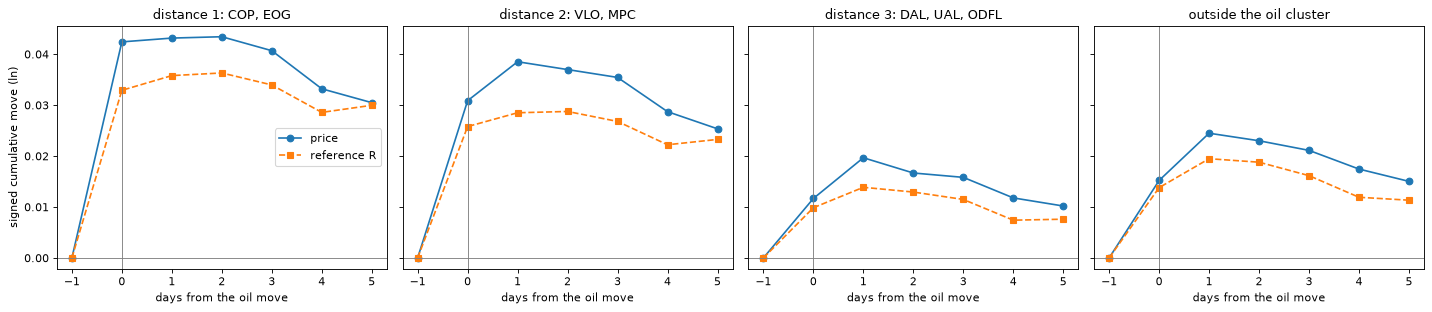

,distance,"R, day 0","price, day 0","price, day 1","price, day 3","R, day 3"
COP,1.0,0.0319,0.0412,0.0406,0.0383,0.0330
EOG,1.0,0.0339,0.0436,0.0458,0.0430,0.0349
VLO,2.0,0.0274,0.0330,0.0405,0.0371,0.0284
MPC,2.0,0.0241,0.0288,0.0366,0.0337,0.0252
DAL,3.0,0.0095,0.0101,0.0185,0.0156,0.0111
UAL,3.0,0.0095,0.0100,0.0209,0.0171,0.0113
ODFL,3.0,0.0106,0.0150,0.0196,0.0148,0.0121


In [7]:
def daily_close(run_dir):
    book = pd.read_parquet(run_dir / "book.parquet", columns=["t", "asset", "best_bid", "best_ask"])
    val = pd.read_parquet(run_dir / "valuations.parquet", columns=["t", "asset", "reference"])
    book = book.loc[(book.best_bid > 0) & (book.best_ask > 0)]
    book = book.assign(mid=(book.best_bid + book.best_ask) / 2, session=np.floor(book.t).astype(int))
    val = val.assign(session=np.floor(val.t).astype(int))
    close = book.groupby(["session", "asset"]).mid.last().unstack()
    ref = val.groupby(["session", "asset"]).reference.last().unstack()
    close.columns, ref.columns = TICKERS, TICKERS
    return np.log(close.loc[:501]), np.log(ref.loc[:501])


def complete(name, n):
    path = RESULTS / name / "summary.csv"
    return path.exists() and len(pd.read_csv(path)) >= n


source = next((d for d, n in (("e5", 270), ("e5_short", 90)) if complete(d, n)), "pilot")
runs = pd.read_csv(RESULTS / source / "summary.csv")
if source == "pilot":
    runs = runs.loc[runs["price_log_change__JPM"].notna() & runs["price_log_change__NVDA"].notna()]
else:
    runs = runs.loc[(runs["agents.composition"] == "mixed") & (runs["agents.herding.h"] == 0.2)]
oil = np.log(real["wti"]).diff()
events = oil.abs().sort_values(ascending=False).index[: round(0.05 * (len(oil) - 1))]
events = [e for e in events if 11 <= e <= 495]
sign = np.sign(oil.loc[events])
offsets = np.arange(-1, 6)
price_resp, ref_resp = [], []
for run_id in runs.run_id:
    close, ref = daily_close(RESULTS / source / run_id)
    for frame, store in ((close, price_resp), (ref, ref_resp)):
        store.append(np.mean([sign[e] * (frame.loc[e + offsets].to_numpy() - frame.loc[e - 1].to_numpy())
                              for e in events], axis=0))
price_resp = pd.DataFrame(np.mean(price_resp, axis=0), index=offsets, columns=TICKERS)
ref_resp = pd.DataFrame(np.mean(ref_resp, axis=0), index=offsets, columns=TICKERS)
print(f"{source}: {len(runs)} runs, {len(events)} events, mean |oil move| {oil.loc[events].abs().mean():.3f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
groups = {"distance 1: COP, EOG": ["COP", "EOG"], "distance 2: VLO, MPC": ["VLO", "MPC"],
          "distance 3: DAL, UAL, ODFL": ["DAL", "UAL", "ODFL"], "outside the oil cluster": OTHERS}
for ax, (title, members) in zip(axes, groups.items()):
    ax.plot(offsets, price_resp[members].mean(axis=1), "o-", label="price")
    ax.plot(offsets, ref_resp[members].mean(axis=1), "s--", label="reference R")
    ax.axvline(0, color="grey", lw=0.8)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("days from the oil move")
axes[0].set_ylabel("signed cumulative move (ln)")
axes[0].legend()
plt.tight_layout()
plt.show()

table = pd.DataFrame({
    "R, day 0": ref_resp.loc[0], "price, day 0": price_resp.loc[0], "price, day 1": price_resp.loc[1],
    "price, day 3": price_resp.loc[3], "R, day 3": ref_resp.loc[3],
})
table.insert(0, "distance", pd.Series(LEVELS))
table.loc[OIL_CLUSTER].round(4)

## What to take from this

- The wave follows the graph and passes **within the day**: the oil producers reach their reference in 0.85
  session, the refiners 0.1 session later; companies outside the oil cluster do not move.
- Prices overshoot the reference by 30–45% for about five sessions (trend followers with a five-session window)
  and then return; the refiners overshoot more because their network valuers read the producers' overshot prices.
- On the real oil days of 2024–2025 the picture is the same but smaller: the oil chain is 20-30% above the
  reference on the day and for the next two or three days, then returns.
- Parameters, calibration and the comparison with the F5 rules: `docs/guides/f6_full_network.md`.